# Week 10 Coding Practice: Can We Trust an Explanation? (Instructor Solution)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/obscrivn/DataScience-book/blob/main/module10/week10_explainability_practice_solution.ipynb)

**Estimated time:** 45-60 minutes
**Format:** ungraded guided practice -- instructor solution, not for student distribution


## Learning objectives

By the end of this activity, students should be able to:

1. evaluate a trained regression model's predictive performance using MAE and R²;
2. compute and interpret permutation feature importance on held-out data;
3. generate and interpret a SHAP waterfall plot for one individual prediction;
4. show how correlated features can distort a permutation-importance-based explanation;
5. write a short, evidence-based assessment of a model's reliability that distinguishes what an explanation shows from whether a prediction is correct.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import shap

plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42

housing = fetch_california_housing(as_frame=True)
df = housing.frame

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

model = RandomForestRegressor(
    n_estimators=200, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1
)
model.fit(X_train, y_train)

print(f"Training rows: {len(X_train)}, test rows: {len(X_test)}")
print(f"Predictors: {list(X.columns)}")


Training rows: 16512, test rows: 4128
Predictors: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [2]:
test_predictions = model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_predictions)
test_r2 = r2_score(y_test, test_predictions)

print(f"Test MAE: {test_mae:.3f} (~${test_mae * 100_000:,.0f})")
print(f"Test R^2: {test_r2:.3f}")


Test MAE: 0.366 (~$36,574)
Test R^2: 0.775


,feature,importance_mean,importance_std
0,MedInc,0.840,0.017
6,Latitude,0.314,0.006
7,Longitude,0.221,0.005
5,AveOccup,0.204,0.006
1,HouseAge,0.068,0.003
2,AveRooms,0.019,0.001
3,AveBedrms,0.007,0.001
4,Population,0.006,0.001


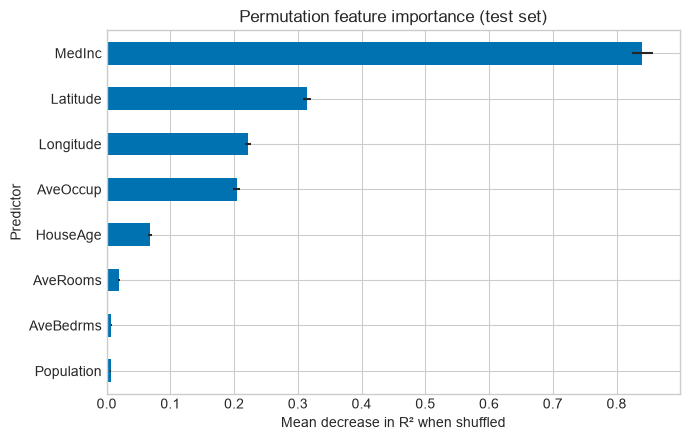

In [3]:
perm_result = permutation_importance(
    model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE
)

importance_table = pd.DataFrame(
    {
        "feature": X_test.columns,
        "importance_mean": perm_result.importances_mean,
        "importance_std": perm_result.importances_std,
    }
).sort_values("importance_mean", ascending=False)

display(importance_table.round(3))

fig, ax = plt.subplots(figsize=(7, 4.5))
importance_table.sort_values("importance_mean").plot.barh(
    x="feature", y="importance_mean", xerr="importance_std",
    ax=ax, legend=False, color="#0072B2",
)
ax.set_xlabel("Mean decrease in R² when shuffled")
ax.set_ylabel("Predictor")
ax.set_title("Permutation feature importance (test set)")
plt.tight_layout()
plt.show()


In [4]:
residuals = pd.DataFrame(
    {"actual": y_test.values, "predicted": test_predictions}, index=y_test.index
)
residuals["abs_error"] = (residuals["actual"] - residuals["predicted"]).abs()

# Exclude rows where the actual value is capped at the dataset maximum (not a real model error).
uncapped = residuals[residuals["actual"] < 5.0]

worst_idx = uncapped["abs_error"].idxmax()

worst_row = residuals.loc[worst_idx]
print(f"Selected row index: {worst_idx}")
print(
    f"Actual: ${worst_row['actual'] * 100_000:,.0f}   "
    f"Predicted: ${worst_row['predicted'] * 100_000:,.0f}   "
    f"Error: ${worst_row['abs_error'] * 100_000:,.0f}"
)
display(X_test.loc[[worst_idx]])


Selected row index: 19542
Actual: $450,000   Predicted: $140,482   Error: $309,518


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
19542,1.7679,39.0,5.0,0.888889,22.0,2.444444,37.63,-120.92


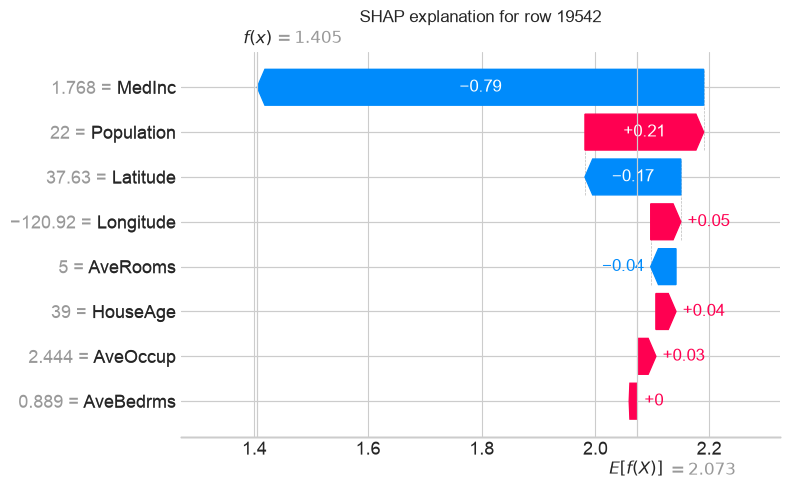

In [5]:
explainer = shap.TreeExplainer(model)
row_to_explain = X_test.loc[[worst_idx]]
shap_explanation = explainer(row_to_explain)

shap.plots.waterfall(shap_explanation[0], show=False)
fig = plt.gcf()
fig.set_size_inches(8, 5)
plt.title(f"SHAP explanation for row {worst_idx}")
plt.tight_layout()
plt.show()


,Shuffled independently (sum),Shuffled together (joint)
R² drop,0.537,0.249


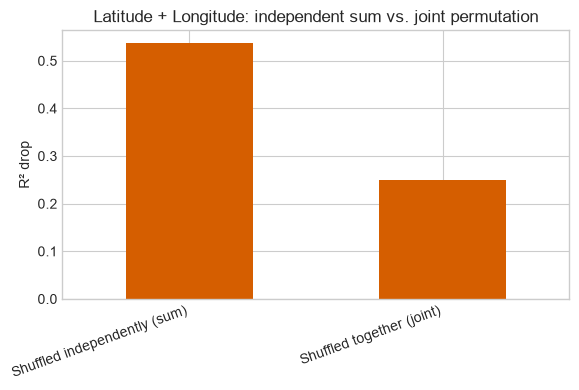

In [6]:
rng = np.random.RandomState(RANDOM_STATE)
baseline_r2 = r2_score(y_test, model.predict(X_test))

def permuted_r2_drop(columns, n_repeats=10):
    # Mean R^2 drop from shuffling `columns` together, `n_repeats` times.
    drops = []
    for _ in range(n_repeats):
        X_shuffled = X_test.copy()
        shuffle_order = rng.permutation(len(X_shuffled))
        for column in columns:
            X_shuffled[column] = X_shuffled[column].values[shuffle_order]
        drops.append(baseline_r2 - r2_score(y_test, model.predict(X_shuffled)))
    return np.mean(drops)

lat_drop = permuted_r2_drop(["Latitude"])
lon_drop = permuted_r2_drop(["Longitude"])
joint_drop = permuted_r2_drop(["Latitude", "Longitude"])

comparison = pd.DataFrame(
    {
        "Shuffled independently (sum)": [lat_drop + lon_drop],
        "Shuffled together (joint)": [joint_drop],
    },
    index=["R² drop"],
)
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
comparison.T.plot.bar(ax=ax, legend=False, color="#D55E00")
ax.set_ylabel("R² drop")
ax.set_title("Latitude + Longitude: independent sum vs. joint permutation")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


## Example instructor response (Step 7)

This is one reasonable answer, provided as a reference point for spot-checking student responses, not the only acceptable answer.

> The model predicts with a typical error of about \$37,000 and explains roughly 78% of the variance in median house value, so it is useful but far from exact. Permutation importance on the test set ranks median income highest, followed by location (latitude/longitude) and average occupancy; these describe what the model leans on, not what causes house values. For the one large-error row examined (actual value far above the prediction), the SHAP waterfall shows which features pushed the prediction up or down relative to the model's average, but it only explains the model's own reasoning, not why the model undershot the true value. The Latitude/Longitude check shows that shuffling the two location features independently overstates their combined importance compared to shuffling them together, so individual importance rankings for correlated features should not be read as if each feature's contribution were separable. More confidence would require checking performance on a held-out set from a different time period or region, and comparing SHAP explanations across several large-error rows rather than just one.
